In [2]:
from pathlib import Path
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize


plt.style.use("seaborn-v0_8-whitegrid")


# Set the path to the Excel file
DATA_PATH = Path("JUN18.xlsx")


# Check whether the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH.resolve()}\n"
        "Place JUN18.xlsx in the same folder as this Python file."
    )


# Inspect the workbook
excel_file = pd.ExcelFile(DATA_PATH)

print("Excel file loaded successfully:")
print(DATA_PATH.resolve())

print("\nAvailable worksheets:")
for sheet_name in excel_file.sheet_names:
    print(" -", sheet_name)


# Load the step-shear worksheet
raw = pd.read_excel(
    DATA_PATH,
    sheet_name="Step Up Step Down",
    header=None,
)

print("\nWorksheet dimensions:")
print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])

print("\nTop-left section of the worksheet:")
print(raw.iloc[:8, :15])

/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Excel file loaded successfully:
/Users/g.y/Desktop/Project team 35/code/JUN18.xlsx

Available worksheets:
 - Steady State & SAOS
 - Helton
 - Step Up Step Down
 - LAOS
 - reversal
 - Cessation 
 - SRFS
 - UDLAOS

Worksheet dimensions:
Rows: 4189
Columns: 69

Top-left section of the worksheet:
              0         1       2           3   4            5         6   \
0  5-->2.5 (1/s)       NaN     NaN         NaN NaN  5-->1 (1/s)       NaN   
1      Step time    Stress  Strain  Shear rate NaN    Step time    Stress   
2              s        Pa       %         1/s NaN            s        Pa   
3       0.000837  0.039103  951645       4.996 NaN     0.000835  0.054081   
4       0.001837  0.038799  951644     4.99401 NaN     0.001842  0.053499   
5       0.002836  0.040082  951645     4.98196 NaN     0.002819  0.052622   
6       0.003835  0.041678  951645     4.93915 NaN     0.003826  0.050679   
7       0.004835  0.042848  951645     4.83517 NaN     0.004833  0.047904   

        7   

In [3]:
# %% Extract measured step experiments

@dataclass(frozen=True)
class StepDefinition:
    start_column: int
    gamma_initial: float
    gamma_final: float
    direction: str

    @property
    def label(self):
        return (
            f"{self.gamma_initial:g} to "
            f"{self.gamma_final:g} 1/s"
        )


STEP_PROTOCOLS = [
    StepDefinition(
        start_column=0,
        gamma_initial=5.0,
        gamma_final=2.5,
        direction="down",
    ),
    StepDefinition(
        start_column=5,
        gamma_initial=5.0,
        gamma_final=1.0,
        direction="down",
    ),
    StepDefinition(
        start_column=20,
        gamma_initial=5.0,
        gamma_final=0.1,
        direction="down",
    ),
    StepDefinition(
        start_column=30,
        gamma_initial=0.25,
        gamma_final=1.0,
        direction="up",
    ),
    StepDefinition(
        start_column=35,
        gamma_initial=0.25,
        gamma_final=2.5,
        direction="up",
    ),
    StepDefinition(
        start_column=40,
        gamma_initial=0.25,
        gamma_final=5.0,
        direction="up",
    ),
]


def load_measured_step(
    worksheet,
    definition,
):
    start_column = (
        definition.start_column
    )

    excel_title = worksheet.iloc[
        0,
        start_column,
    ]

    block = worksheet.iloc[
        3:68,
        start_column:start_column + 4,
    ].copy()

    block.columns = [
        "time_s",
        "stress_pa",
        "strain_percent",
        "shear_rate_per_s",
    ]

    for column in block.columns:
        block[column] = pd.to_numeric(
            block[column],
            errors="coerce",
        )

    block = block.dropna(
        subset=[
            "time_s",
            "stress_pa",
            "shear_rate_per_s",
        ]
    )

    block = (
        block
        .sort_values("time_s")
        .drop_duplicates(
            subset="time_s"
        )
        .reset_index(drop=True)
    )

    return (
        str(excel_title),
        block,
    )


experiments = []
audit_rows = []


for definition in STEP_PROTOCOLS:
    excel_title, measured_data = (
        load_measured_step(
            raw,
            definition,
        )
    )

    experiments.append(
        (
            definition,
            measured_data,
        )
    )

    initial_rate_median = float(
        measured_data[
            "shear_rate_per_s"
        ]
        .iloc[:5]
        .median()
    )

    final_rate_median = float(
        measured_data[
            "shear_rate_per_s"
        ]
        .iloc[-10:]
        .median()
    )

    audit_rows.append(
        {
            "step": definition.label,
            "direction": definition.direction,
            "excel_title": excel_title,
            "points": len(measured_data),
            "time_min_s": measured_data[
                "time_s"
            ].min(),
            "time_max_s": measured_data[
                "time_s"
            ].max(),
            "initial_rate_median": (
                initial_rate_median
            ),
            "final_rate_median": (
                final_rate_median
            ),
            "rate_min_per_s": measured_data[
                "shear_rate_per_s"
            ].min(),
            "rate_max_per_s": measured_data[
                "shear_rate_per_s"
            ].max(),
        }
    )


audit_table = pd.DataFrame(
    audit_rows
)


print("Measured step experiments:")

print(
    audit_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print()
print(
    f"Number of experiments: "
    f"{len(experiments)}"
)

print(
    f"Total number of points: "
    f"{sum(len(data) for _, data in experiments)}"
)


for definition, measured_data in experiments:
    if len(measured_data) != 65:
        raise ValueError(
            f"Unexpected point count for "
            f"{definition.label}: "
            f"{len(measured_data)}"
        )

    if not np.all(
        np.diff(
            measured_data["time_s"]
        ) > 0.0
    ):
        raise ValueError(
            f"Time is not strictly increasing for "
            f"{definition.label}"
        )

    final_rate_median = float(
        measured_data[
            "shear_rate_per_s"
        ]
        .iloc[-10:]
        .median()
    )

    final_rate_tolerance = max(
        0.05,
        0.05
        * definition.gamma_final,
    )

    if not np.isclose(
        final_rate_median,
        definition.gamma_final,
        atol=final_rate_tolerance,
        rtol=0.0,
    ):
        raise ValueError(
            f"Final measured rate does not match "
            f"the protocol for {definition.label}"
        )


assert len(experiments) == 6

assert sum(
    len(data)
    for _, data in experiments
) == 390


print()
print(
    "All measured-data validation checks passed."
)

Measured step experiments:
           step direction    excel_title  points  time_min_s  time_max_s  initial_rate_median  final_rate_median  rate_min_per_s  rate_max_per_s
   5 to 2.5 1/s      down  5-->2.5 (1/s)      65    0.000837   63.000700             4.981960           2.500300        2.375070        4.996000
     5 to 1 1/s      down    5-->1 (1/s)      65    0.000835   63.000700             4.984110           1.000120        0.791631        4.993680
   5 to 0.1 1/s      down    5-->.1(1/s)      65    0.000860   63.001200             4.985820           0.100012       -0.154079        5.007540
  0.25 to 1 1/s        up   .25-->1(1/s)      65    0.000782   63.000700             0.252448           1.000120        0.249601        1.039690
0.25 to 2.5 1/s        up .25-->2.5(1/s)      65    0.000774   63.000700             0.258890           2.500295        0.249677        2.620950
  0.25 to 5 1/s        up   .25-->5(1/s)      65    0.000826   63.000700             0.266481          

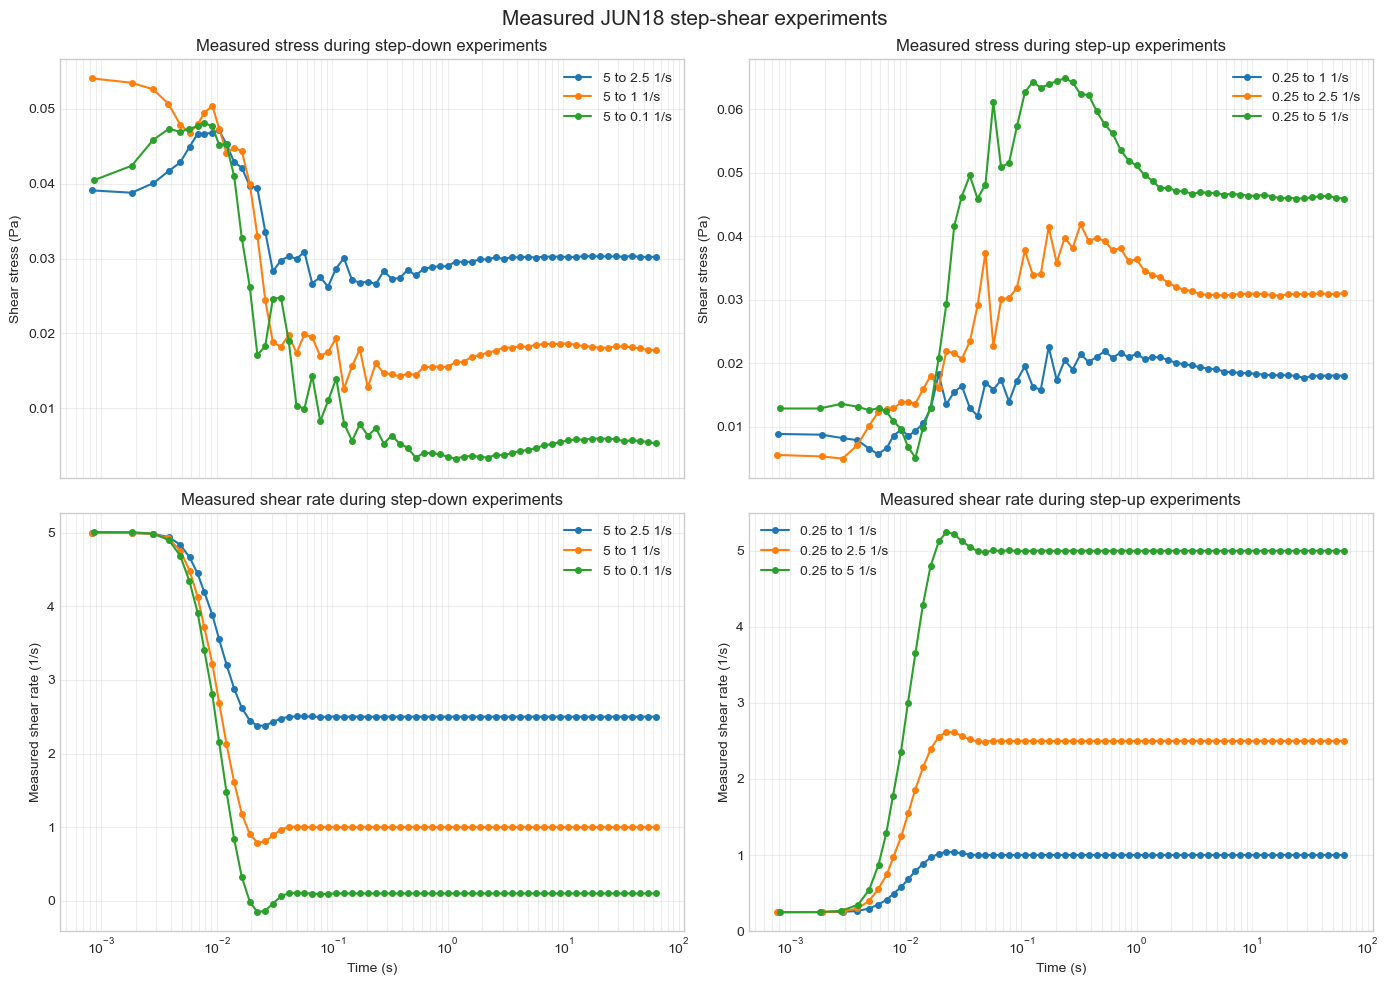

In [4]:
# %% Plot measured stress and shear rate

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    sharex=True,
)

stress_down_axis = axes[0, 0]
stress_up_axis = axes[0, 1]
rate_down_axis = axes[1, 0]
rate_up_axis = axes[1, 1]


for definition, measured_data in experiments:
    if definition.direction == "down":
        stress_axis = stress_down_axis
        rate_axis = rate_down_axis
    else:
        stress_axis = stress_up_axis
        rate_axis = rate_up_axis

    stress_axis.semilogx(
        measured_data["time_s"],
        measured_data["stress_pa"],
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=definition.label,
    )

    rate_axis.semilogx(
        measured_data["time_s"],
        measured_data["shear_rate_per_s"],
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=definition.label,
    )


stress_down_axis.set_title(
    "Measured stress during step-down experiments"
)

stress_up_axis.set_title(
    "Measured stress during step-up experiments"
)

rate_down_axis.set_title(
    "Measured shear rate during step-down experiments"
)

rate_up_axis.set_title(
    "Measured shear rate during step-up experiments"
)


for axis in [
    stress_down_axis,
    stress_up_axis,
]:
    axis.set_ylabel("Shear stress (Pa)")
    axis.grid(
        True,
        which="both",
        alpha=0.35,
    )
    axis.legend()


for axis in [
    rate_down_axis,
    rate_up_axis,
]:
    axis.set_xlabel("Time (s)")
    axis.set_ylabel("Measured shear rate (1/s)")
    axis.grid(
        True,
        which="both",
        alpha=0.35,
    )
    axis.legend()


fig.suptitle(
    "Measured JUN18 step-shear experiments",
    fontsize=15,
)

plt.tight_layout()
plt.show()

In [5]:
# %% Define Table 5 parameters

@dataclass(frozen=True)
class TETVPParameters:
    eta_inf: float
    sigma_y0: float
    tr1: float
    tr2: float
    eta_st: float
    d: float
    m: float
    tau_lambda: float
    G: float


PUBLISHED = TETVPParameters(
    eta_inf=0.0032,
    sigma_y0=0.0026,
    tr1=0.2496,
    tr2=0.0521,
    eta_st=0.0180,
    d=0.5,
    m=1.5,
    tau_lambda=0.5540,
    G=0.2133,
)


PUBLISHED_TRANSIENT_COST = 0.000370


parameter_table = pd.DataFrame(
    {
        "parameter": [
            "eta_inf",
            "sigma_y0",
            "tr1",
            "tr2",
            "eta_st",
            "d",
            "m",
            "tau_lambda",
            "G",
        ],
        "value": [
            PUBLISHED.eta_inf,
            PUBLISHED.sigma_y0,
            PUBLISHED.tr1,
            PUBLISHED.tr2,
            PUBLISHED.eta_st,
            PUBLISHED.d,
            PUBLISHED.m,
            PUBLISHED.tau_lambda,
            PUBLISHED.G,
        ],
        "unit": [
            "Pa s",
            "Pa",
            "s",
            "s^(1/2)",
            "Pa s",
            "dimensionless",
            "dimensionless",
            "s",
            "Pa",
        ],
        "role": [
            "Infinite-shear viscosity",
            "Yield-stress scale",
            "Shear-breakdown ratio",
            "Shear-aggregation ratio",
            "Structural viscosity",
            "Aggregation exponent",
            "Structural-viscosity exponent",
            "Structure evolution time",
            "Elastic modulus",
        ],
    }
)


print("Published Table 5 parameters:")

print(
    parameter_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print()
print(
    f"Published transient cost: "
    f"{PUBLISHED_TRANSIENT_COST:.6f}"
)


positive_parameters = [
    PUBLISHED.eta_inf,
    PUBLISHED.sigma_y0,
    PUBLISHED.tr1,
    PUBLISHED.tr2,
    PUBLISHED.eta_st,
    PUBLISHED.tau_lambda,
    PUBLISHED.G,
]


assert all(
    value > 0.0
    for value in positive_parameters
)

assert PUBLISHED.d == 0.5
assert PUBLISHED.m == 1.5


print()
print(
    "Published parameter validation passed."
)

Published Table 5 parameters:
 parameter    value          unit                          role
   eta_inf 0.003200          Pa s      Infinite-shear viscosity
  sigma_y0 0.002600            Pa            Yield-stress scale
       tr1 0.249600             s         Shear-breakdown ratio
       tr2 0.052100       s^(1/2)       Shear-aggregation ratio
    eta_st 0.018000          Pa s          Structural viscosity
         d 0.500000 dimensionless          Aggregation exponent
         m 1.500000 dimensionless Structural-viscosity exponent
tau_lambda 0.554000             s      Structure evolution time
         G 0.213300            Pa               Elastic modulus

Published transient cost: 0.000370

Published parameter validation passed.


Measured and predicted steady-state stress:
           step direction  measured_rate_per_s  measured_stress_pa  predicted_stress_pa  residual_pa
   5 to 2.5 1/s      down             2.500300            0.030277             0.032385     0.002108
     5 to 1 1/s      down             1.000120            0.018102             0.018382     0.000280
   5 to 0.1 1/s      down             0.100012            0.005722             0.004594    -0.001128
  0.25 to 1 1/s        up             1.000120            0.018014             0.018382     0.000368
0.25 to 2.5 1/s        up             2.500295            0.030875             0.032385     0.001510
  0.25 to 5 1/s        up             5.000590            0.046038             0.046433     0.000395

Steady-state RMSE: 0.001181 Pa


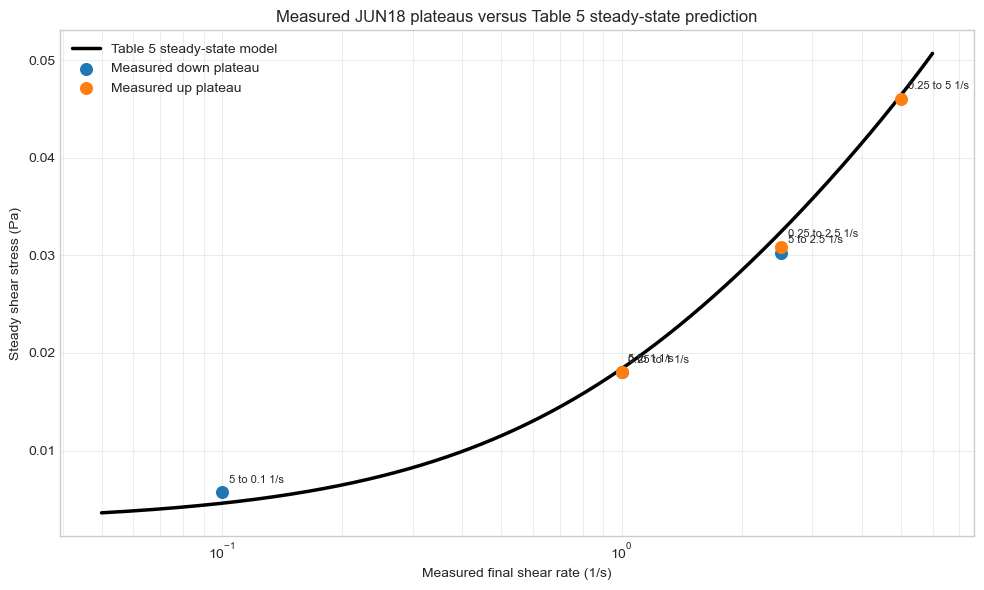


Steady-state equation validation completed.


In [6]:
# %% Implement and validate steady-state equations

def lambda_steady_state(
    shear_rate,
    parameters=PUBLISHED,
):
    shear_rate = np.asarray(
        shear_rate,
        dtype=float,
    )

    absolute_rate = np.abs(
        shear_rate
    )

    aggregation = (
        parameters.tr2
        * absolute_rate ** parameters.d
        + 1.0
    )

    breakdown = (
        parameters.tr1
        * absolute_rate
    )

    return (
        aggregation
        / (
            breakdown
            + aggregation
        )
    )


def steady_stress_components(
    shear_rate,
    parameters=PUBLISHED,
):
    shear_rate = np.asarray(
        shear_rate,
        dtype=float,
    )

    lambda_value = lambda_steady_state(
        shear_rate,
        parameters,
    )

    infinite_shear_component = (
        parameters.eta_inf
        * shear_rate
    )

    structural_viscous_component = (
        parameters.eta_st
        * lambda_value ** parameters.m
        * shear_rate
    )

    yield_component = (
        parameters.sigma_y0
        * lambda_value
    )

    total_stress = (
        infinite_shear_component
        + structural_viscous_component
        + yield_component
    )

    return {
        "lambda_ss": lambda_value,
        "infinite_shear_pa": (
            infinite_shear_component
        ),
        "structural_viscous_pa": (
            structural_viscous_component
        ),
        "yield_pa": yield_component,
        "total_stress_pa": total_stress,
    }


def steady_stress(
    shear_rate,
    parameters=PUBLISHED,
):
    return steady_stress_components(
        shear_rate,
        parameters,
    )["total_stress_pa"]


steady_state_rows = []


for definition, measured_data in experiments:
    final_rate_median = float(
        measured_data[
            "shear_rate_per_s"
        ]
        .iloc[-10:]
        .median()
    )

    measured_stress_median = float(
        measured_data[
            "stress_pa"
        ]
        .iloc[-10:]
        .median()
    )

    predicted_stress = float(
        steady_stress(
            final_rate_median,
            PUBLISHED,
        )
    )

    steady_state_rows.append(
        {
            "step": definition.label,
            "direction": definition.direction,
            "measured_rate_per_s": (
                final_rate_median
            ),
            "measured_stress_pa": (
                measured_stress_median
            ),
            "predicted_stress_pa": (
                predicted_stress
            ),
            "residual_pa": (
                predicted_stress
                - measured_stress_median
            ),
        }
    )


steady_state_comparison = pd.DataFrame(
    steady_state_rows
)


steady_state_rmse = float(
    np.sqrt(
        np.mean(
            steady_state_comparison[
                "residual_pa"
            ] ** 2
        )
    )
)


print("Measured and predicted steady-state stress:")

print(
    steady_state_comparison.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print()
print(
    f"Steady-state RMSE: "
    f"{steady_state_rmse:.6f} Pa"
)


rate_curve = np.logspace(
    np.log10(0.05),
    np.log10(6.0),
    500,
)

predicted_curve = steady_stress(
    rate_curve,
    PUBLISHED,
)


fig, axis = plt.subplots(
    figsize=(10, 6)
)

axis.semilogx(
    rate_curve,
    predicted_curve,
    color="black",
    linewidth=2.5,
    label="Table 5 steady-state model",
)


direction_colors = {
    "down": "tab:blue",
    "up": "tab:orange",
}


for direction in [
    "down",
    "up",
]:
    subset = steady_state_comparison[
        steady_state_comparison[
            "direction"
        ] == direction
    ]

    axis.scatter(
        subset["measured_rate_per_s"],
        subset["measured_stress_pa"],
        color=direction_colors[direction],
        s=70,
        label=f"Measured {direction} plateau",
        zorder=5,
    )


for _, row in steady_state_comparison.iterrows():
    axis.annotate(
        row["step"],
        xy=(
            row["measured_rate_per_s"],
            row["measured_stress_pa"],
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=8,
    )


axis.set_title(
    "Measured JUN18 plateaus versus Table 5 steady-state prediction"
)

axis.set_xlabel(
    "Measured final shear rate (1/s)"
)

axis.set_ylabel(
    "Steady shear stress (Pa)"
)

axis.grid(
    True,
    which="both",
    alpha=0.35,
)

axis.legend()

plt.tight_layout()
plt.show()


assert np.all(
    (
        lambda_steady_state(
            rate_curve,
            PUBLISHED,
        ) >= 0.0
    )
    & (
        lambda_steady_state(
            rate_curve,
            PUBLISHED,
        ) <= 1.0
    )
)

assert np.isfinite(
    steady_state_rmse
)


print()
print(
    "Steady-state equation validation completed."
)

Representative experiment:
0.25 to 5 1/s

Initial conditions:
Initial measured shear rate: 0.248480 1/s
Initial measured stress: 0.012848 Pa
Initial predicted lambda: 0.942995

Representative RMSE: 0.004975 Pa


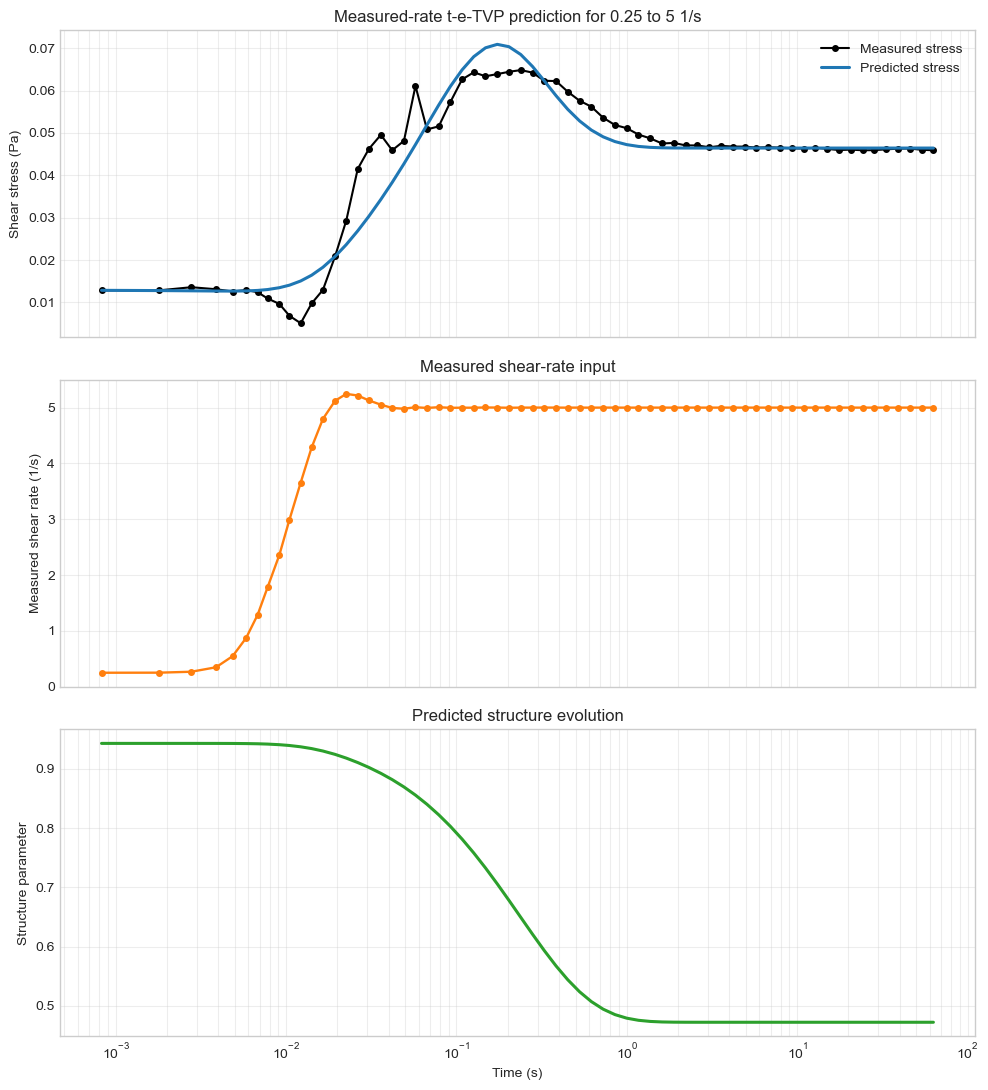


Measured-rate transient solver validation passed.


In [7]:
# %% Solve one measured-rate experiment

def simulate_measured_experiment(
    definition,
    measured_data,
    parameters=PUBLISHED,
):
    time_values = measured_data[
        "time_s"
    ].to_numpy(dtype=float)

    measured_rate = measured_data[
        "shear_rate_per_s"
    ].to_numpy(dtype=float)

    measured_stress = measured_data[
        "stress_pa"
    ].to_numpy(dtype=float)

    relative_time = (
        time_values
        - time_values[0]
    )

    if not np.all(
        np.diff(relative_time) > 0.0
    ):
        raise ValueError(
            "Time values must be strictly increasing."
        )

    initial_rate = float(
        measured_rate[0]
    )

    initial_lambda = float(
        lambda_steady_state(
            initial_rate,
            parameters,
        )
    )

    initial_stress = float(
        measured_stress[0]
    )

    def measured_rate_function(
        current_time,
    ):
        return float(
            np.interp(
                current_time,
                relative_time,
                measured_rate,
            )
        )

    def model_rhs(
        current_time,
        state,
    ):
        lambda_value = float(
            np.clip(
                state[0],
                1e-12,
                1.0,
            )
        )

        stress_value = float(
            state[1]
        )

        current_rate = (
            measured_rate_function(
                current_time
            )
        )

        absolute_rate = abs(
            current_rate
        )

        aggregation = (
            parameters.tr2
            * absolute_rate
            ** parameters.d
            + 1.0
        )

        breakdown = (
            parameters.tr1
            * absolute_rate
        )

        lambda_derivative = (
            aggregation
            * (1.0 - lambda_value)
            - breakdown
            * lambda_value
        ) / parameters.tau_lambda

        effective_viscosity = (
            parameters.eta_inf
            + parameters.eta_st
            * lambda_value
            ** parameters.m
        )

        target_stress = (
            parameters.sigma_y0
            * lambda_value
            + effective_viscosity
            * current_rate
        )

        stress_derivative = (
            parameters.G
            / effective_viscosity
            * (
                target_stress
                - stress_value
            )
        )

        return [
            lambda_derivative,
            stress_derivative,
        ]

    solution = solve_ivp(
        fun=model_rhs,
        t_span=(
            0.0,
            float(relative_time[-1]),
        ),
        y0=[
            initial_lambda,
            initial_stress,
        ],
        t_eval=relative_time,
        method="LSODA",
        rtol=1e-9,
        atol=1e-11,
    )

    if not solution.success:
        raise RuntimeError(
            solution.message
        )

    prediction = pd.DataFrame(
        {
            "time_s": time_values,
            "relative_time_s": relative_time,
            "measured_rate_per_s": measured_rate,
            "measured_stress_pa": measured_stress,
            "predicted_lambda": solution.y[0],
            "predicted_stress_pa": solution.y[1],
        }
    )

    return prediction


representative_definition = None
representative_data = None


for definition, measured_data in experiments:
    if (
        definition.gamma_initial == 0.25
        and definition.gamma_final == 5.0
    ):
        representative_definition = definition
        representative_data = measured_data
        break


if representative_definition is None:
    raise ValueError(
        "Representative experiment was not found."
    )


representative_prediction = (
    simulate_measured_experiment(
        definition=representative_definition,
        measured_data=representative_data,
        parameters=PUBLISHED,
    )
)


representative_residual = (
    representative_prediction[
        "predicted_stress_pa"
    ]
    - representative_prediction[
        "measured_stress_pa"
    ]
)


representative_rmse = float(
    np.sqrt(
        np.mean(
            representative_residual ** 2
        )
    )
)


print("Representative experiment:")
print(
    representative_definition.label
)

print()
print("Initial conditions:")

print(
    f"Initial measured shear rate: "
    f"{representative_prediction['measured_rate_per_s'].iloc[0]:.6f} 1/s"
)

print(
    f"Initial measured stress: "
    f"{representative_prediction['measured_stress_pa'].iloc[0]:.6f} Pa"
)

print(
    f"Initial predicted lambda: "
    f"{representative_prediction['predicted_lambda'].iloc[0]:.6f}"
)

print()
print(
    f"Representative RMSE: "
    f"{representative_rmse:.6f} Pa"
)


fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 11),
    sharex=True,
)


axes[0].semilogx(
    representative_prediction["time_s"],
    representative_prediction[
        "measured_stress_pa"
    ],
    color="black",
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Measured stress",
)

axes[0].semilogx(
    representative_prediction["time_s"],
    representative_prediction[
        "predicted_stress_pa"
    ],
    color="tab:blue",
    linewidth=2.2,
    label="Predicted stress",
)

axes[0].set_ylabel(
    "Shear stress (Pa)"
)

axes[0].set_title(
    "Measured-rate t-e-TVP prediction for 0.25 to 5 1/s"
)

axes[0].legend()


axes[1].semilogx(
    representative_prediction["time_s"],
    representative_prediction[
        "measured_rate_per_s"
    ],
    color="tab:orange",
    marker="o",
    markersize=4,
    linewidth=1.7,
)

axes[1].set_ylabel(
    "Measured shear rate (1/s)"
)

axes[1].set_title(
    "Measured shear-rate input"
)


axes[2].semilogx(
    representative_prediction["time_s"],
    representative_prediction[
        "predicted_lambda"
    ],
    color="tab:green",
    linewidth=2.2,
)

axes[2].set_xlabel(
    "Time (s)"
)

axes[2].set_ylabel(
    "Structure parameter"
)

axes[2].set_title(
    "Predicted structure evolution"
)


for axis in axes:
    axis.grid(
        True,
        which="both",
        alpha=0.35,
    )


plt.tight_layout()
plt.show()


assert np.all(
    representative_prediction[
        "predicted_lambda"
    ] >= 0.0
)

assert np.all(
    representative_prediction[
        "predicted_lambda"
    ] <= 1.0
)

assert np.isclose(
    representative_prediction[
        "predicted_stress_pa"
    ].iloc[0],
    representative_prediction[
        "measured_stress_pa"
    ].iloc[0],
)


print()
print(
    "Measured-rate transient solver validation passed."
)

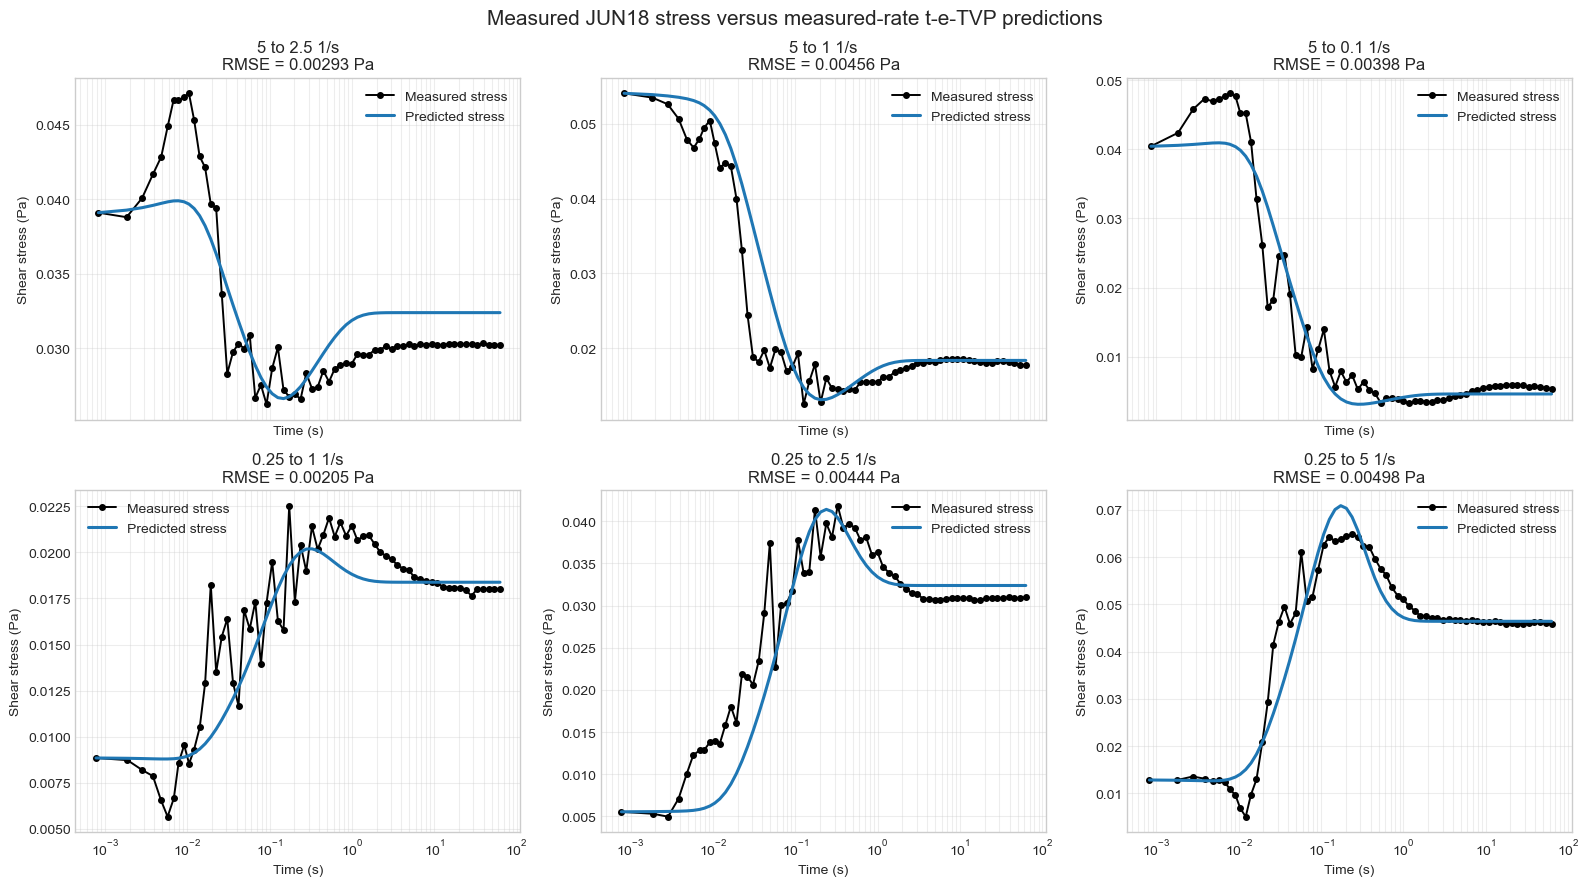

Per-step transient metrics:
           step direction  points  rmse_pa   mae_pa   bias_pa  maximum_absolute_error_pa  sse_pa2
   5 to 2.5 1/s      down      65 0.002933 0.002436  0.000422                   0.007445 0.000559
     5 to 1 1/s      down      65 0.004560 0.002583  0.002114                   0.017489 0.001352
   5 to 0.1 1/s      down      65 0.003981 0.002725 -0.000755                   0.014480 0.001030
  0.25 to 1 1/s        up      65 0.002046 0.001463 -0.000691                   0.008249 0.000272
0.25 to 2.5 1/s        up      65 0.004436 0.003193 -0.001585                   0.015777 0.001279
  0.25 to 5 1/s        up      65 0.004975 0.003080 -0.000621                   0.015893 0.001609

Overall transient metrics:
Total points: 390
Global RMSE: 0.003955 Pa
Global MAE: 0.002580 Pa
Global bias: -0.000186 Pa
Total SSE: 0.006102 Pa^2

All measured-rate transient predictions completed.


In [8]:
# %% Predict all six measured experiments

measured_predictions = {}
transient_metric_rows = []
all_transient_residuals = []


fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9),
    sharex=True,
)

axes = axes.flatten()


for axis, (
    definition,
    measured_data,
) in zip(
    axes,
    experiments,
):
    prediction = (
        simulate_measured_experiment(
            definition=definition,
            measured_data=measured_data,
            parameters=PUBLISHED,
        )
    )

    residual = (
        prediction[
            "predicted_stress_pa"
        ]
        - prediction[
            "measured_stress_pa"
        ]
    ).to_numpy(dtype=float)

    prediction = prediction.copy()

    prediction[
        "residual_pa"
    ] = residual

    measured_predictions[
        definition.label
    ] = prediction

    rmse = float(
        np.sqrt(
            np.mean(
                residual ** 2
            )
        )
    )

    mae = float(
        np.mean(
            np.abs(residual)
        )
    )

    bias = float(
        np.mean(residual)
    )

    maximum_absolute_error = float(
        np.max(
            np.abs(residual)
        )
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    transient_metric_rows.append(
        {
            "step": definition.label,
            "direction": definition.direction,
            "points": len(prediction),
            "rmse_pa": rmse,
            "mae_pa": mae,
            "bias_pa": bias,
            "maximum_absolute_error_pa": (
                maximum_absolute_error
            ),
            "sse_pa2": sse,
        }
    )

    all_transient_residuals.append(
        residual
    )

    axis.semilogx(
        prediction["time_s"],
        prediction[
            "measured_stress_pa"
        ],
        color="black",
        marker="o",
        markersize=4,
        linewidth=1.4,
        label="Measured stress",
    )

    axis.semilogx(
        prediction["time_s"],
        prediction[
            "predicted_stress_pa"
        ],
        color="tab:blue",
        linewidth=2.2,
        label="Predicted stress",
    )

    axis.set_title(
        f"{definition.label}\n"
        f"RMSE = {rmse:.5f} Pa"
    )

    axis.set_xlabel(
        "Time (s)"
    )

    axis.set_ylabel(
        "Shear stress (Pa)"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.35,
    )

    axis.legend()


fig.suptitle(
    "Measured JUN18 stress versus measured-rate t-e-TVP predictions",
    fontsize=15,
)

plt.tight_layout()
plt.show()


transient_metrics = pd.DataFrame(
    transient_metric_rows
)


combined_transient_residuals = (
    np.concatenate(
        all_transient_residuals
    )
)


global_transient_rmse = float(
    np.sqrt(
        np.mean(
            combined_transient_residuals ** 2
        )
    )
)

global_transient_mae = float(
    np.mean(
        np.abs(
            combined_transient_residuals
        )
    )
)

global_transient_bias = float(
    np.mean(
        combined_transient_residuals
    )
)

total_transient_sse = float(
    np.sum(
        combined_transient_residuals ** 2
    )
)


print("Per-step transient metrics:")

print(
    transient_metrics.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print()
print("Overall transient metrics:")

print(
    f"Total points: "
    f"{len(combined_transient_residuals)}"
)

print(
    f"Global RMSE: "
    f"{global_transient_rmse:.6f} Pa"
)

print(
    f"Global MAE: "
    f"{global_transient_mae:.6f} Pa"
)

print(
    f"Global bias: "
    f"{global_transient_bias:.6f} Pa"
)

print(
    f"Total SSE: "
    f"{total_transient_sse:.6f} Pa^2"
)


assert len(
    measured_predictions
) == 6

assert len(
    combined_transient_residuals
) == 390

assert np.isfinite(
    global_transient_rmse
)


print()
print(
    "All measured-rate transient predictions completed."
)

In [9]:
# %% Calculate the exact Equation 18 cost

equation_18_rows = []


for _, row in transient_metrics.iterrows():
    point_count = int(
        row["points"]
    )

    sse = float(
        row["sse_pa2"]
    )

    rmse = float(
        row["rmse_pa"]
    )

    equation_18_step_cost = float(
        np.sqrt(sse)
        / point_count
    )

    equivalent_step_cost = float(
        rmse
        / np.sqrt(point_count)
    )

    equation_18_rows.append(
        {
            "step": row["step"],
            "direction": row["direction"],
            "points": point_count,
            "rmse_pa": rmse,
            "sqrt_sse_pa": np.sqrt(sse),
            "equation_18_step_cost": (
                equation_18_step_cost
            ),
            "equivalent_step_cost": (
                equivalent_step_cost
            ),
        }
    )


equation_18_table = pd.DataFrame(
    equation_18_rows
)


calculated_transient_cost = float(
    equation_18_table[
        "equation_18_step_cost"
    ].mean()
)


cost_absolute_difference = float(
    calculated_transient_cost
    - PUBLISHED_TRANSIENT_COST
)


cost_relative_difference_percent = float(
    100.0
    * cost_absolute_difference
    / PUBLISHED_TRANSIENT_COST
)


print("Equation 18 cost by experiment:")

print(
    equation_18_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.8f}",
    )
)

print()
print("Transient cost comparison:")

print(
    f"Calculated Equation 18 cost: "
    f"{calculated_transient_cost:.8f}"
)

print(
    f"Published Table 5 cost: "
    f"{PUBLISHED_TRANSIENT_COST:.8f}"
)

print(
    f"Absolute difference: "
    f"{cost_absolute_difference:.8f}"
)

print(
    f"Relative difference: "
    f"{cost_relative_difference_percent:.2f}%"
)


formula_check_error = float(
    np.max(
        np.abs(
            equation_18_table[
                "equation_18_step_cost"
            ]
            - equation_18_table[
                "equivalent_step_cost"
            ]
        )
    )
)


print()
print(
    f"Equation equivalence check error: "
    f"{formula_check_error:.3e}"
)


assert np.isclose(
    calculated_transient_cost,
    equation_18_table[
        "equation_18_step_cost"
    ].sum()
    / len(equation_18_table),
)

assert formula_check_error < 1e-12

assert calculated_transient_cost > 0.0


print()
print(
    "Equation 18 transient cost calculation completed."
)

Equation 18 cost by experiment:
           step direction  points    rmse_pa  sqrt_sse_pa  equation_18_step_cost  equivalent_step_cost
   5 to 2.5 1/s      down      65 0.00293340   0.02364986             0.00036384            0.00036384
     5 to 1 1/s      down      65 0.00455997   0.03676364             0.00056559            0.00056559
   5 to 0.1 1/s      down      65 0.00398148   0.03209973             0.00049384            0.00049384
  0.25 to 1 1/s        up      65 0.00204621   0.01649704             0.00025380            0.00025380
0.25 to 2.5 1/s        up      65 0.00443645   0.03576778             0.00055027            0.00055027
  0.25 to 5 1/s        up      65 0.00497532   0.04011231             0.00061711            0.00061711

Transient cost comparison:
Calculated Equation 18 cost: 0.00047408
Published Table 5 cost: 0.00037000
Absolute difference: 0.00010408
Relative difference: 28.13%

Equation equivalence check error: 1.084e-19

Equation 18 transient cost calculation

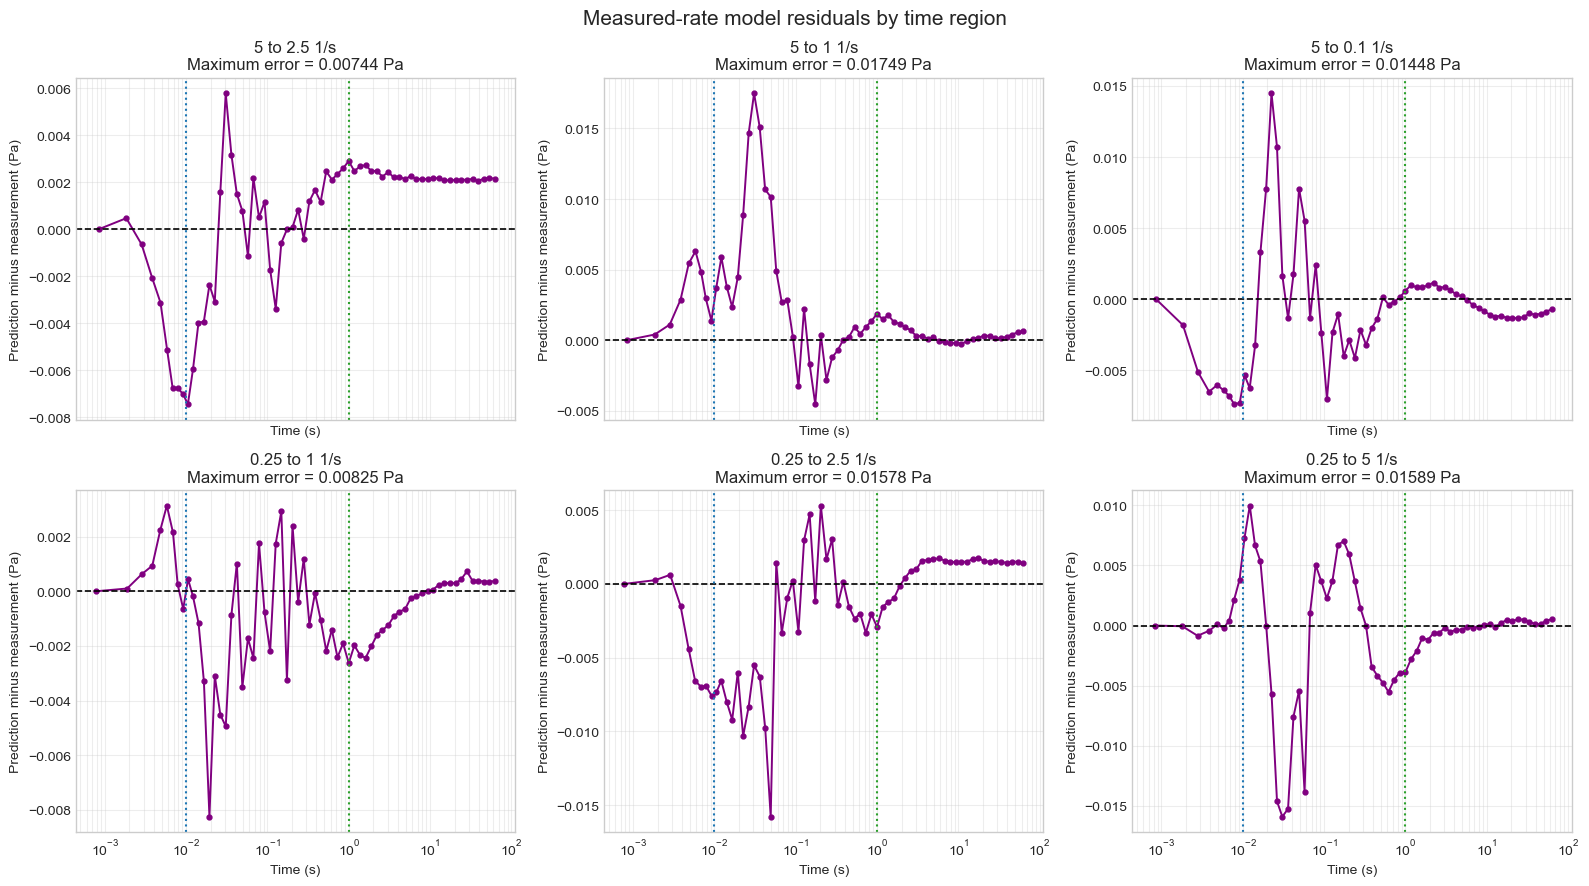

Residual metrics by time window:
time_window  points  rmse_pa   mae_pa   bias_pa  sse_pa2  sse_percentage
      Early      54 0.003986 0.002917 -0.001341 0.000858       14.059665
 Transition     180 0.005259 0.003808 -0.000394 0.004978       81.578573
       Late     156 0.001306 0.001047  0.000454 0.000266        4.361762

Residual metrics by step direction:
direction  points  rmse_pa   mae_pa   bias_pa  sse_pa2
     down     195 0.003884 0.002581  0.000594 0.002941
       up     195 0.004026 0.002579 -0.000966 0.003160

Largest SSE window: Transition
Highest RMSE window: Transition

Measured-rate residual analysis completed.


In [10]:
# %% Analyze residuals by time region

time_window_order = [
    "Early",
    "Transition",
    "Late",
]


residual_frames = []


for definition, _ in experiments:
    prediction = measured_predictions[
        definition.label
    ].copy()

    prediction["step"] = (
        definition.label
    )

    prediction["direction"] = (
        definition.direction
    )

    prediction["time_window"] = pd.cut(
        prediction["time_s"],
        bins=[
            -np.inf,
            0.01,
            1.0,
            np.inf,
        ],
        labels=time_window_order,
        right=False,
    )

    prediction[
        "absolute_error_pa"
    ] = np.abs(
        prediction["residual_pa"]
    )

    prediction[
        "squared_error_pa2"
    ] = (
        prediction["residual_pa"]
        ** 2
    )

    residual_frames.append(
        prediction
    )


all_residual_data = pd.concat(
    residual_frames,
    ignore_index=True,
)


time_window_rows = []


for window_name in time_window_order:
    window_data = all_residual_data[
        all_residual_data[
            "time_window"
        ] == window_name
    ]

    window_sse = float(
        window_data[
            "squared_error_pa2"
        ].sum()
    )

    window_rmse = float(
        np.sqrt(
            np.mean(
                window_data[
                    "squared_error_pa2"
                ]
            )
        )
    )

    window_mae = float(
        window_data[
            "absolute_error_pa"
        ].mean()
    )

    window_bias = float(
        window_data[
            "residual_pa"
        ].mean()
    )

    sse_percentage = float(
        100.0
        * window_sse
        / total_transient_sse
    )

    time_window_rows.append(
        {
            "time_window": window_name,
            "points": len(window_data),
            "rmse_pa": window_rmse,
            "mae_pa": window_mae,
            "bias_pa": window_bias,
            "sse_pa2": window_sse,
            "sse_percentage": (
                sse_percentage
            ),
        }
    )


time_window_metrics = pd.DataFrame(
    time_window_rows
)


direction_rows = []


for direction in [
    "down",
    "up",
]:
    direction_data = all_residual_data[
        all_residual_data[
            "direction"
        ] == direction
    ]

    direction_sse = float(
        direction_data[
            "squared_error_pa2"
        ].sum()
    )

    direction_rmse = float(
        np.sqrt(
            np.mean(
                direction_data[
                    "squared_error_pa2"
                ]
            )
        )
    )

    direction_mae = float(
        direction_data[
            "absolute_error_pa"
        ].mean()
    )

    direction_bias = float(
        direction_data[
            "residual_pa"
        ].mean()
    )

    direction_rows.append(
        {
            "direction": direction,
            "points": len(direction_data),
            "rmse_pa": direction_rmse,
            "mae_pa": direction_mae,
            "bias_pa": direction_bias,
            "sse_pa2": direction_sse,
        }
    )


direction_metrics = pd.DataFrame(
    direction_rows
)


fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9),
    sharex=True,
)

axes = axes.flatten()


for axis, (
    definition,
    _,
) in zip(
    axes,
    experiments,
):
    prediction = measured_predictions[
        definition.label
    ]

    axis.semilogx(
        prediction["time_s"],
        prediction["residual_pa"],
        color="purple",
        marker="o",
        markersize=3.5,
        linewidth=1.4,
    )

    axis.axhline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1.2,
    )

    axis.axvline(
        0.01,
        color="tab:blue",
        linestyle=":",
        linewidth=1.5,
        label="0.01 s",
    )

    axis.axvline(
        1.0,
        color="tab:green",
        linestyle=":",
        linewidth=1.5,
        label="1 s",
    )

    maximum_absolute_error = float(
        np.max(
            np.abs(
                prediction[
                    "residual_pa"
                ]
            )
        )
    )

    axis.set_title(
        f"{definition.label}\n"
        f"Maximum error = "
        f"{maximum_absolute_error:.5f} Pa"
    )

    axis.set_xlabel(
        "Time (s)"
    )

    axis.set_ylabel(
        "Prediction minus measurement (Pa)"
    )

    axis.grid(
        True,
        which="both",
        alpha=0.35,
    )


fig.suptitle(
    "Measured-rate model residuals by time region",
    fontsize=15,
)

plt.tight_layout()
plt.show()


print("Residual metrics by time window:")

print(
    time_window_metrics.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print()
print("Residual metrics by step direction:")

print(
    direction_metrics.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)


largest_sse_window = (
    time_window_metrics
    .sort_values(
        "sse_pa2",
        ascending=False,
    )
    .iloc[0][
        "time_window"
    ]
)

highest_rmse_window = (
    time_window_metrics
    .sort_values(
        "rmse_pa",
        ascending=False,
    )
    .iloc[0][
        "time_window"
    ]
)


print()
print(
    f"Largest SSE window: "
    f"{largest_sse_window}"
)

print(
    f"Highest RMSE window: "
    f"{highest_rmse_window}"
)


assert (
    time_window_metrics[
        "points"
    ].sum()
    == 390
)

assert np.isclose(
    time_window_metrics[
        "sse_pa2"
    ].sum(),
    total_transient_sse,
)

assert (
    direction_metrics[
        "points"
    ].sum()
    == 390
)


print()
print(
    "Measured-rate residual analysis completed."
)

In [11]:
# %% Create the final reproducibility summary

best_step_row = (
    transient_metrics
    .sort_values(
        "rmse_pa",
        ascending=True,
    )
    .iloc[0]
)

worst_step_row = (
    transient_metrics
    .sort_values(
        "rmse_pa",
        ascending=False,
    )
    .iloc[0]
)


early_row = (
    time_window_metrics[
        time_window_metrics[
            "time_window"
        ] == "Early"
    ]
    .iloc[0]
)

transition_row = (
    time_window_metrics[
        time_window_metrics[
            "time_window"
        ] == "Transition"
    ]
    .iloc[0]
)

late_row = (
    time_window_metrics[
        time_window_metrics[
            "time_window"
        ] == "Late"
    ]
    .iloc[0]
)

down_row = (
    direction_metrics[
        direction_metrics[
            "direction"
        ] == "down"
    ]
    .iloc[0]
)

up_row = (
    direction_metrics[
        direction_metrics[
            "direction"
        ] == "up"
    ]
    .iloc[0]
)


final_summary = pd.DataFrame(
    {
        "metric": [
            "Number of experiments",
            "Total transient points",
            "Steady-state RMSE",
            "Global transient RMSE",
            "Global transient MAE",
            "Global transient bias",
            "Calculated Equation 18 cost",
            "Published Table 5 cost",
            "Cost difference",
            "Early SSE percentage",
            "Transition SSE percentage",
            "Late SSE percentage",
            "Step-down RMSE",
            "Step-up RMSE",
        ],
        "value": [
            len(experiments),
            len(combined_transient_residuals),
            steady_state_rmse,
            global_transient_rmse,
            global_transient_mae,
            global_transient_bias,
            calculated_transient_cost,
            PUBLISHED_TRANSIENT_COST,
            cost_relative_difference_percent,
            early_row["sse_percentage"],
            transition_row["sse_percentage"],
            late_row["sse_percentage"],
            down_row["rmse_pa"],
            up_row["rmse_pa"],
        ],
        "unit": [
            "experiments",
            "points",
            "Pa",
            "Pa",
            "Pa",
            "Pa",
            "cost units",
            "cost units",
            "%",
            "%",
            "%",
            "%",
            "Pa",
            "Pa",
        ],
    }
)


print("Final Task 4 summary:")

print(
    final_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.8f}",
    )
)

print()
print(
    f"Best predicted experiment: "
    f"{best_step_row['step']}"
)

print(
    f"Best experiment RMSE: "
    f"{best_step_row['rmse_pa']:.6f} Pa"
)

print()
print(
    f"Worst predicted experiment: "
    f"{worst_step_row['step']}"
)

print(
    f"Worst experiment RMSE: "
    f"{worst_step_row['rmse_pa']:.6f} Pa"
)

print()
print(
    "Reproduction classification: "
    "qualitatively successful, "
    "quantitatively incomplete"
)

print(
    "Primary error location: "
    "transient region from 0.01 to 1 s"
)

print(
    "Recommended parameter set: "
    "published Table 5 parameters"
)


assert (
    transition_row[
        "sse_percentage"
    ]
    > early_row[
        "sse_percentage"
    ]
)

assert (
    transition_row[
        "sse_percentage"
    ]
    > late_row[
        "sse_percentage"
    ]
)

assert (
    calculated_transient_cost
    > PUBLISHED_TRANSIENT_COST
)


print()
print(
    "Revised measured-rate Task 4 completed."
)

Final Task 4 summary:
                     metric        value        unit
      Number of experiments   6.00000000 experiments
     Total transient points 390.00000000      points
          Steady-state RMSE   0.00118093          Pa
      Global transient RMSE   0.00395544          Pa
       Global transient MAE   0.00257999          Pa
      Global transient bias  -0.00018599          Pa
Calculated Equation 18 cost   0.00047408  cost units
     Published Table 5 cost   0.00037000  cost units
            Cost difference  28.12914125           %
       Early SSE percentage  14.05966500           %
  Transition SSE percentage  81.57857307           %
        Late SSE percentage   4.36176193           %
             Step-down RMSE   0.00388374          Pa
               Step-up RMSE   0.00402587          Pa

Best predicted experiment: 0.25 to 1 1/s
Best experiment RMSE: 0.002046 Pa

Worst predicted experiment: 0.25 to 5 1/s
Worst experiment RMSE: 0.004975 Pa

Reproduction classification:

In [15]:
# Identify the existing measured- and predicted-stress columns.
measured_column = next(
    column
    for column in all_residual_data.columns
    if "stress" in column.lower()
    and "measured" in column.lower()
)

predicted_column = next(
    column
    for column in all_residual_data.columns
    if "stress" in column.lower()
    and (
        "predicted" in column.lower()
        or "model" in column.lower()
    )
)


def calculate_r2(data):
    measured = data[measured_column].to_numpy(float)
    predicted = data[predicted_column].to_numpy(float)

    return 1.0 - (
        np.sum((measured - predicted) ** 2)
        / np.sum((measured - measured.mean()) ** 2)
    )


r2_results = pd.DataFrame(
    [
        {
            "step": step,
            "direction": direction,
            "r2": calculate_r2(data),
        }
        for (step, direction), data
        in all_residual_data.groupby(
            ["step", "direction"],
            sort=False,
        )
    ]
)


global_r2 = calculate_r2(all_residual_data)


display(r2_results.round(6))

print(f"Global R-squared: {global_r2:.6f}")

,step,direction,r2
0,5 to 2.5 1/s,down,0.764206
1,5 to 1 1/s,down,0.875661
2,5 to 0.1 1/s,down,0.935629
3,0.25 to 1 1/s,up,0.794657
4,0.25 to 2.5 1/s,up,0.793347
5,0.25 to 5 1/s,up,0.918657


Global R-squared: 0.933030


In [16]:
lag_values = np.linspace(
    -0.020,
    0.020,
    81,
)


def shift_prediction(data, lag):
    data = data.sort_values(
        "relative_time_s"
    )

    time = data[
        "relative_time_s"
    ].to_numpy(float)

    predicted = data[
        predicted_column
    ].to_numpy(float)

    shifted_prediction = np.interp(
        time - lag,
        time,
        predicted,
        left=predicted[0],
        right=predicted[-1],
    )

    return shifted_prediction


def calculate_array_metrics(
    measured,
    predicted,
):
    residual = predicted - measured

    rmse = np.sqrt(
        np.mean(residual ** 2)
    )

    r2 = 1.0 - (
        np.sum(residual ** 2)
        / np.sum(
            (measured - measured.mean()) ** 2
        )
    )

    return rmse, r2


global_lag_rows = []


for lag in lag_values:
    measured_groups = []
    shifted_groups = []
    tier_costs = []

    for _, data in all_residual_data.groupby(
        "step",
        sort=False,
    ):
        data = data.sort_values(
            "relative_time_s"
        )

        measured = data[
            measured_column
        ].to_numpy(float)

        shifted = shift_prediction(
            data,
            lag,
        )

        residual = shifted - measured

        measured_groups.append(measured)
        shifted_groups.append(shifted)

        tier_costs.append(
            np.linalg.norm(residual) / len(data)
        )

    measured_all = np.concatenate(
        measured_groups
    )

    shifted_all = np.concatenate(
        shifted_groups
    )

    rmse, r2 = calculate_array_metrics(
        measured_all,
        shifted_all,
    )

    global_lag_rows.append(
        {
            "lag_s": lag,
            "rmse_pa": rmse,
            "r2": r2,
            "equation_18_cost": np.mean(
                tier_costs
            ),
        }
    )


global_lag_results = pd.DataFrame(
    global_lag_rows
)


baseline = global_lag_results.loc[
    np.isclose(
        global_lag_results["lag_s"],
        0.0,
    )
].iloc[0]

best_global = global_lag_results.loc[
    global_lag_results["rmse_pa"].idxmin()
]


global_alignment_summary = pd.DataFrame(
    [
        {
            "setting": "No time shift",
            **baseline.to_dict(),
        },
        {
            "setting": "Best global shift",
            **best_global.to_dict(),
        },
    ]
)


display(
    global_alignment_summary.round(6)
)


rmse_improvement = (
    baseline["rmse_pa"]
    - best_global["rmse_pa"]
) / baseline["rmse_pa"] * 100


print(
    f"Best global lag: "
    f"{best_global['lag_s']:.4f} s"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement:.2f}%"
)

step_alignment_rows = []


for (step, direction), data in (
    all_residual_data.groupby(
        ["step", "direction"],
        sort=False,
    )
):
    data = data.sort_values(
        "relative_time_s"
    )

    measured = data[
        measured_column
    ].to_numpy(float)

    lag_rmse_rows = []

    for lag in lag_values:
        shifted = shift_prediction(
            data,
            lag,
        )

        rmse, _ = calculate_array_metrics(
            measured,
            shifted,
        )

        lag_rmse_rows.append(
            {
                "lag_s": lag,
                "rmse_pa": rmse,
            }
        )

    lag_rmse_table = pd.DataFrame(
        lag_rmse_rows
    )

    baseline_rmse = lag_rmse_table.loc[
        np.isclose(
            lag_rmse_table["lag_s"],
            0.0,
        ),
        "rmse_pa",
    ].iloc[0]

    best_row = lag_rmse_table.loc[
        lag_rmse_table["rmse_pa"].idxmin()
    ]

    improvement = (
        baseline_rmse
        - best_row["rmse_pa"]
    ) / baseline_rmse * 100

    step_alignment_rows.append(
        {
            "step": step,
            "direction": direction,
            "best_lag_s": best_row["lag_s"],
            "baseline_rmse_pa": baseline_rmse,
            "best_rmse_pa": best_row["rmse_pa"],
            "improvement_percent": improvement,
        }
    )


step_alignment_results = pd.DataFrame(
    step_alignment_rows
)

display(
    step_alignment_results.round(6)
)

,setting,lag_s,rmse_pa,r2,equation_18_cost
0,No time shift,0.000,0.003955,0.933030,0.000474
1,Best global shift,-0.005,0.003680,0.942047,0.000442


Best global lag: -0.0050 s
RMSE improvement: 6.98%


,step,direction,best_lag_s,baseline_rmse_pa,best_rmse_pa,improvement_percent
0,5 to 2.5 1/s,down,0.001,0.002933,0.002929,0.161059
1,5 to 1 1/s,down,-0.009,0.004560,0.003205,29.721526
2,5 to 0.1 1/s,down,-0.002,0.003981,0.003911,1.769869
3,0.25 to 1 1/s,up,-0.010,0.002046,0.001892,7.518391
4,0.25 to 2.5 1/s,up,-0.016,0.004436,0.002705,39.033287
5,0.25 to 5 1/s,up,-0.003,0.004975,0.004853,2.465128


In [17]:
from scipy.interpolate import PchipInterpolator


parameter_values = (
    parameter_table
    .set_index("parameter")["value"]
    .astype(float)
    .to_dict()
)


rate_column = next(
    column
    for column in all_residual_data.columns
    if "rate" in column.lower()
    and "measured" in column.lower()
)


def simulate_interpolation_method(
    data,
    method,
):
    data = data.sort_values(
        "relative_time_s"
    )

    time = data[
        "relative_time_s"
    ].to_numpy(float)

    measured_rate = data[
        rate_column
    ].to_numpy(float)

    measured_stress = data[
        measured_column
    ].to_numpy(float)

    if method == "Linear":
        rate_function = lambda t: np.interp(
            t,
            time,
            measured_rate,
        )

    elif method == "PCHIP":
        interpolator = PchipInterpolator(
            time,
            measured_rate,
            extrapolate=True,
        )

        rate_function = lambda t: float(
            interpolator(t)
        )

    else:
        raise ValueError(
            f"Unknown interpolation method: {method}"
        )

    def lambda_steady_state(rate):
        absolute_rate = abs(rate)

        build = (
            parameter_values["tr2"]
            * absolute_rate
            ** parameter_values["d"]
            + 1.0
        )

        return build / (
            parameter_values["tr1"]
            * absolute_rate
            + build
        )

    initial_lambda = lambda_steady_state(
        measured_rate[0]
    )

    initial_stress = measured_stress[0]

    def rhs(current_time, state):
        lam, stress = state

        rate = rate_function(
            current_time
        )

        absolute_rate = abs(rate)

        build = (
            parameter_values["tr2"]
            * absolute_rate
            ** parameter_values["d"]
            + 1.0
        )

        d_lambda = (
            build
            - (
                build
                + parameter_values["tr1"]
                * absolute_rate
            )
            * lam
        ) / parameter_values["tau_lambda"]

        effective_viscosity = (
            parameter_values["eta_st"]
            * max(lam, 0.0)
            ** parameter_values["m"]
            + parameter_values["eta_inf"]
        )

        d_stress = (
            parameter_values["G"]
            / effective_viscosity
            * (
                lam
                * parameter_values["sigma_y0"]
                + effective_viscosity
                * rate
                - stress
            )
        )

        return [
            d_lambda,
            d_stress,
        ]

    solution = solve_ivp(
        rhs,
        (
            time[0],
            time[-1],
        ),
        [
            initial_lambda,
            initial_stress,
        ],
        t_eval=time,
        method="LSODA",
        rtol=2e-9,
        atol=1e-11,
    )

    if not solution.success:
        raise RuntimeError(
            solution.message
        )

    return solution.y[1]


interpolation_rows = []


for method in ["Linear", "PCHIP"]:
    measured_groups = []
    predicted_groups = []
    tier_costs = []

    for _, data in all_residual_data.groupby(
        "step",
        sort=False,
    ):
        data = data.sort_values(
            "relative_time_s"
        )

        measured = data[
            measured_column
        ].to_numpy(float)

        predicted = simulate_interpolation_method(
            data,
            method,
        )

        residual = predicted - measured

        measured_groups.append(measured)
        predicted_groups.append(predicted)

        tier_costs.append(
            np.linalg.norm(residual) / len(data)
        )

    measured_all = np.concatenate(
        measured_groups
    )

    predicted_all = np.concatenate(
        predicted_groups
    )

    rmse, r2 = calculate_array_metrics(
        measured_all,
        predicted_all,
    )

    interpolation_rows.append(
        {
            "method": method,
            "rmse_pa": rmse,
            "r2": r2,
            "equation_18_cost": np.mean(
                tier_costs
            ),
        }
    )


interpolation_results = pd.DataFrame(
    interpolation_rows
)


linear_rmse = interpolation_results.loc[
    interpolation_results["method"] == "Linear",
    "rmse_pa",
].iloc[0]


interpolation_results[
    "rmse_improvement_percent"
] = (
    linear_rmse
    - interpolation_results["rmse_pa"]
) / linear_rmse * 100


display(
    interpolation_results.round(8)
)

,method,rmse_pa,r2,equation_18_cost,rmse_improvement_percent
0,Linear,0.003955,0.933030,0.000474,0.000000
1,PCHIP,0.003951,0.933178,0.000474,0.110922


In [18]:
# Block 14 — Initialisation sensitivity

def lambda_steady_state(rate):
    rate = abs(rate)
    build = parameter_values["tr2"] * rate ** parameter_values["d"] + 1.0
    return build / (parameter_values["tr1"] * rate + build)


def stress_steady_state(rate):
    lam = lambda_steady_state(rate)
    return (
        parameter_values["sigma_y0"] * lam
        + parameter_values["eta_st"] * lam ** parameter_values["m"] * rate
        + parameter_values["eta_inf"] * rate
    )


def simulate_with_initialisation(method):
    predicted = pd.Series(index=all_residual_data.index, dtype=float)

    for _, block in all_residual_data.groupby("step", sort=False):
        block = block.sort_values("relative_time_s")

        time = block["relative_time_s"].to_numpy(float)
        rate = block[rate_column].to_numpy(float)
        measured = block[measured_column].to_numpy(float)

        if method == "First 3-point median":
            initial_rate = float(np.median(rate[:3]))
            lambda_0 = lambda_steady_state(initial_rate)
            stress_0 = float(np.median(measured[:3]))

        elif method == "Theoretical steady state":
            initial_rate = float(str(block["step"].iloc[0]).split()[0])
            lambda_0 = lambda_steady_state(initial_rate)
            stress_0 = stress_steady_state(initial_rate)

        else:
            raise ValueError("Unknown initialisation method")

        def rhs(t, state):
            lam, stress = state
            current_rate = float(np.interp(t, time, rate))
            absolute_rate = abs(current_rate)

            build = (
                parameter_values["tr2"]
                * absolute_rate ** parameter_values["d"]
                + 1.0
            )

            d_lambda = (
                build
                - (build + parameter_values["tr1"] * absolute_rate) * lam
            ) / parameter_values["tau_lambda"]

            effective_viscosity = (
                parameter_values["eta_st"] * max(lam, 0.0) ** parameter_values["m"]
                + parameter_values["eta_inf"]
            )

            d_stress = (
                parameter_values["G"]
                / effective_viscosity
                * (
                    parameter_values["sigma_y0"] * lam
                    + effective_viscosity * current_rate
                    - stress
                )
            )

            return [d_lambda, d_stress]

        solution = solve_ivp(
            rhs,
            (time[0], time[-1]),
            [lambda_0, stress_0],
            t_eval=time,
            method="LSODA",
            rtol=2e-9,
            atol=1e-11,
            max_step=0.01,
        )

        if not solution.success:
            raise RuntimeError(solution.message)

        predicted.loc[block.index] = solution.y[1]

    return predicted.loc[all_residual_data.index].to_numpy(float)


def summarise_initialisation(predicted):
    measured = all_residual_data[measured_column].to_numpy(float)
    residual = predicted - measured

    rmse = np.sqrt(np.mean(residual ** 2))
    r2 = 1.0 - (
        np.sum(residual ** 2)
        / np.sum((measured - measured.mean()) ** 2)
    )

    predicted_series = pd.Series(
        predicted,
        index=all_residual_data.index,
    )

    tier_costs = []
    for _, block in all_residual_data.groupby("step", sort=False):
        block_residual = (
            predicted_series.loc[block.index].to_numpy(float)
            - block[measured_column].to_numpy(float)
        )
        tier_costs.append(
            np.linalg.norm(block_residual) / len(block)
        )

    return rmse, r2, np.mean(tier_costs)


# Reuse the existing baseline prediction
baseline_prediction = all_residual_data[predicted_column].to_numpy(float)

predictions = {
    "First measured point": baseline_prediction,
    "First 3-point median": simulate_with_initialisation(
        "First 3-point median"
    ),
    "Theoretical steady state": simulate_with_initialisation(
        "Theoretical steady state"
    ),
}

initialisation_rows = []

for method, predicted in predictions.items():
    rmse, r2, equation_18_cost = summarise_initialisation(predicted)

    initialisation_rows.append(
        {
            "method": method,
            "rmse_pa": rmse,
            "r2": r2,
            "equation_18_cost": equation_18_cost,
        }
    )

initialisation_table = pd.DataFrame(initialisation_rows)

baseline_rmse = initialisation_table.loc[
    initialisation_table["method"] == "First measured point",
    "rmse_pa",
].iloc[0]

initialisation_table["rmse_improvement_percent"] = (
    100.0
    * (baseline_rmse - initialisation_table["rmse_pa"])
    / baseline_rmse
)

display(initialisation_table.round(6))

,method,rmse_pa,r2,equation_18_cost,rmse_improvement_percent
0,First measured point,0.003955,0.933030,0.000474,0.00000
1,First 3-point median,0.003924,0.934079,0.000471,0.78627
2,Theoretical steady state,0.003972,0.932472,0.000473,-0.41523


In [19]:
# Block 15 — ODE solver tolerance sensitivity

def simulate_model(parameters, rtol, atol):
    predicted = pd.Series(index=all_residual_data.index, dtype=float)

    for _, block in all_residual_data.groupby("step", sort=False):
        block = block.sort_values("relative_time_s")

        time = block["relative_time_s"].to_numpy(float)
        rate = block[rate_column].to_numpy(float)
        measured = block[measured_column].to_numpy(float)

        initial_rate = rate[0]
        absolute_initial_rate = abs(initial_rate)

        initial_build = (
            parameters["tr2"]
            * absolute_initial_rate ** parameters["d"]
            + 1.0
        )

        lambda_0 = initial_build / (
            parameters["tr1"] * absolute_initial_rate
            + initial_build
        )

        stress_0 = measured[0]

        def rhs(t, state):
            lam, stress = state
            current_rate = float(np.interp(t, time, rate))
            absolute_rate = abs(current_rate)

            build = (
                parameters["tr2"]
                * absolute_rate ** parameters["d"]
                + 1.0
            )

            d_lambda = (
                build
                - (build + parameters["tr1"] * absolute_rate) * lam
            ) / parameters["tau_lambda"]

            effective_viscosity = (
                parameters["eta_st"]
                * max(lam, 0.0) ** parameters["m"]
                + parameters["eta_inf"]
            )

            d_stress = (
                parameters["G"]
                / effective_viscosity
                * (
                    parameters["sigma_y0"] * lam
                    + effective_viscosity * current_rate
                    - stress
                )
            )

            return [d_lambda, d_stress]

        solution = solve_ivp(
            rhs,
            (time[0], time[-1]),
            [lambda_0, stress_0],
            t_eval=time,
            method="LSODA",
            rtol=rtol,
            atol=atol,
            max_step=0.01,
        )

        if not solution.success:
            raise RuntimeError(solution.message)

        predicted.loc[block.index] = solution.y[1]

    return predicted.loc[all_residual_data.index].to_numpy(float)


# Reuse the existing baseline prediction
solver_predictions = {
    "Baseline": all_residual_data[predicted_column].to_numpy(float),
    "Loose tolerance": simulate_model(
        parameter_values,
        rtol=1e-6,
        atol=1e-8,
    ),
    "Strict tolerance": simulate_model(
        parameter_values,
        rtol=1e-10,
        atol=1e-12,
    ),
}

solver_rows = []

for setting, predicted in solver_predictions.items():
    rmse, r2, equation_18_cost = summarise_initialisation(predicted)

    solver_rows.append(
        {
            "setting": setting,
            "rmse_pa": rmse,
            "r2": r2,
            "equation_18_cost": equation_18_cost,
        }
    )

solver_tolerance_table = pd.DataFrame(solver_rows)

baseline_rmse = solver_tolerance_table.loc[
    solver_tolerance_table["setting"] == "Baseline",
    "rmse_pa",
].iloc[0]

solver_tolerance_table["rmse_change_percent"] = (
    100.0
    * (
        solver_tolerance_table["rmse_pa"]
        - baseline_rmse
    )
    / baseline_rmse
)

display(
    solver_tolerance_table.round(
        {
            "rmse_pa": 9,
            "r2": 9,
            "equation_18_cost": 9,
            "rmse_change_percent": 6,
        }
    )
)

,setting,rmse_pa,r2,equation_18_cost,rmse_change_percent
0,Baseline,0.003955,0.93303,0.000474,0.000000
1,Loose tolerance,0.003955,0.93303,0.000474,0.000132
2,Strict tolerance,0.003955,0.93303,0.000474,-0.000001


In [20]:
# Block 16 — Parameter sensitivity screening

sensitivity_parameters = [
    "eta_inf",
    "sigma_y0",
    "tr1",
    "tr2",
    "eta_st",
    "tau_lambda",
    "G",
]

sensitivity_factors = [0.8, 0.9, 1.1, 1.2]

measured_all = all_residual_data[measured_column].to_numpy(float)
relative_time_all = all_residual_data["relative_time_s"].to_numpy(float)

transition_mask = (
    (relative_time_all >= 0.01)
    & (relative_time_all < 1.0)
)

late_mask = relative_time_all >= 1.0

step_values = all_residual_data["step"].to_numpy()
step_positions = [
    np.flatnonzero(step_values == step)
    for step in pd.unique(step_values)
]


def evaluate_sensitivity_prediction(predicted):
    residual = predicted - measured_all

    global_rmse = np.sqrt(np.mean(residual ** 2))
    transition_rmse = np.sqrt(
        np.mean(residual[transition_mask] ** 2)
    )
    late_rmse = np.sqrt(
        np.mean(residual[late_mask] ** 2)
    )

    equation_18_cost = np.mean(
        [
            np.linalg.norm(residual[position]) / len(position)
            for position in step_positions
        ]
    )

    return {
        "global_rmse_pa": global_rmse,
        "transition_rmse_pa": transition_rmse,
        "late_rmse_pa": late_rmse,
        "equation_18_cost": equation_18_cost,
    }


baseline_prediction = all_residual_data[
    predicted_column
].to_numpy(float)

baseline_sensitivity_metrics = evaluate_sensitivity_prediction(
    baseline_prediction
)

sensitivity_rows = []

for parameter in sensitivity_parameters:
    published_value = parameter_values[parameter]

    for factor in sensitivity_factors:
        modified_parameters = parameter_values.copy()
        modified_parameters[parameter] = published_value * factor

        predicted = simulate_model(
            modified_parameters,
            rtol=1e-6,
            atol=1e-8,
        )

        metrics = evaluate_sensitivity_prediction(predicted)

        sensitivity_rows.append(
            {
                "parameter": parameter,
                "published_value": published_value,
                "factor": factor,
                "tested_value": modified_parameters[parameter],
                **metrics,
            }
        )

    print(f"Completed: {parameter}")


sensitivity_results = pd.DataFrame(sensitivity_rows)

for metric in [
    "global_rmse_pa",
    "transition_rmse_pa",
    "late_rmse_pa",
    "equation_18_cost",
]:
    baseline_value = baseline_sensitivity_metrics[metric]

    sensitivity_results[f"{metric}_change_percent"] = (
        100.0
        * (
            sensitivity_results[metric]
            - baseline_value
        )
        / baseline_value
    )


ranking_rows = []

for parameter in sensitivity_parameters:
    parameter_results = sensitivity_results[
        sensitivity_results["parameter"] == parameter
    ]

    best_row = parameter_results.loc[
        parameter_results["transition_rmse_pa"].idxmin()
    ]

    ranking_rows.append(
        {
            "parameter": parameter,
            "published_value": parameter_values[parameter],
            "maximum_absolute_transition_change_percent":
                parameter_results[
                    "transition_rmse_pa_change_percent"
                ].abs().max(),
            "best_factor": best_row["factor"],
            "best_tested_value": best_row["tested_value"],
            "best_transition_rmse_pa":
                best_row["transition_rmse_pa"],
            "transition_improvement_percent":
                -best_row[
                    "transition_rmse_pa_change_percent"
                ],
            "late_rmse_change_percent":
                best_row["late_rmse_pa_change_percent"],
        }
    )


sensitivity_ranking = (
    pd.DataFrame(ranking_rows)
    .sort_values(
        "maximum_absolute_transition_change_percent",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    sensitivity_ranking.round(
        {
            "published_value": 6,
            "maximum_absolute_transition_change_percent": 3,
            "best_factor": 2,
            "best_tested_value": 6,
            "best_transition_rmse_pa": 6,
            "transition_improvement_percent": 3,
            "late_rmse_change_percent": 3,
        }
    )
)

Completed: eta_inf
Completed: sigma_y0
Completed: tr1
Completed: tr2
Completed: eta_st
Completed: tau_lambda
Completed: G


,parameter,published_value,maximum_absolute_transition_change_percent,best_factor,best_tested_value,best_transition_rmse_pa,transition_improvement_percent,late_rmse_change_percent
0,eta_st,0.0180,23.014,0.9,0.01620,0.005338,-1.925,37.164
1,G,0.2133,17.239,1.2,0.25596,0.004842,7.554,0.120
2,tr1,0.2496,12.374,1.1,0.27456,0.005219,0.366,6.572
3,eta_inf,0.0032,5.562,0.9,0.00288,0.005195,0.822,-1.998
4,tau_lambda,0.5540,1.381,1.1,0.60940,0.005245,-0.146,-1.310
5,tr2,0.0521,0.474,0.8,0.04168,0.005216,0.405,-3.848
6,sigma_y0,0.0026,0.398,1.2,0.00312,0.005231,0.121,11.965


In [21]:
# Block 17 — One-parameter optimisation of G

from scipy.optimize import minimize_scalar

published_G = parameter_values["G"]
g_evaluation_cache = {}


def evaluate_G(candidate_G):
    cache_key = round(float(candidate_G), 10)

    if cache_key not in g_evaluation_cache:
        candidate_parameters = parameter_values.copy()
        candidate_parameters["G"] = float(candidate_G)

        prediction = simulate_model(
            candidate_parameters,
            rtol=1e-6,
            atol=1e-8,
        )

        metrics = evaluate_sensitivity_prediction(prediction)

        g_evaluation_cache[cache_key] = {
            "prediction": prediction,
            "metrics": metrics,
        }

    return g_evaluation_cache[cache_key]


def G_objective(candidate_G):
    result = evaluate_G(candidate_G)
    return result["metrics"]["transition_rmse_pa"]


G_optimisation = minimize_scalar(
    G_objective,
    bounds=(0.5 * published_G, 2.0 * published_G),
    method="bounded",
    options={
        "xatol": 1e-5,
        "maxiter": 50,
    },
)

optimised_G = float(G_optimisation.x)
optimised_G_result = evaluate_G(optimised_G)
optimised_G_prediction = optimised_G_result["prediction"]

optimised_G_parameters = parameter_values.copy()
optimised_G_parameters["G"] = optimised_G


def model_comparison_row(method, G_value, prediction):
    metrics = evaluate_sensitivity_prediction(prediction)
    residual = prediction - measured_all

    r2 = 1.0 - (
        np.sum(residual ** 2)
        / np.sum((measured_all - measured_all.mean()) ** 2)
    )

    return {
        "method": method,
        "G_pa": G_value,
        "G_factor": G_value / published_G,
        "global_rmse_pa": metrics["global_rmse_pa"],
        "transition_rmse_pa": metrics["transition_rmse_pa"],
        "late_rmse_pa": metrics["late_rmse_pa"],
        "r2": r2,
        "equation_18_cost": metrics["equation_18_cost"],
    }


G_comparison = pd.DataFrame(
    [
        model_comparison_row(
            "Published G",
            published_G,
            baseline_prediction,
        ),
        model_comparison_row(
            "Optimised G",
            optimised_G,
            optimised_G_prediction,
        ),
    ]
)

baseline_row = G_comparison.iloc[0]

for metric in [
    "global_rmse_pa",
    "transition_rmse_pa",
    "late_rmse_pa",
    "equation_18_cost",
]:
    G_comparison[f"{metric}_improvement_percent"] = (
        100.0
        * (
            baseline_row[metric]
            - G_comparison[metric]
        )
        / baseline_row[metric]
    )

print(f"Optimisation successful: {G_optimisation.success}")
print(f"Published G: {published_G:.6f} Pa")
print(f"Optimised G: {optimised_G:.6f} Pa")
print(f"G factor: {optimised_G / published_G:.4f}")

display(
    G_comparison.round(
        {
            "G_pa": 6,
            "G_factor": 4,
            "global_rmse_pa": 6,
            "transition_rmse_pa": 6,
            "late_rmse_pa": 6,
            "r2": 6,
            "equation_18_cost": 8,
            "global_rmse_pa_improvement_percent": 3,
            "transition_rmse_pa_improvement_percent": 3,
            "late_rmse_pa_improvement_percent": 3,
            "equation_18_cost_improvement_percent": 3,
        }
    )
)

Optimisation successful: True
Published G: 0.213300 Pa
Optimised G: 0.280472 Pa
G factor: 1.3149


,method,G_pa,G_factor,global_rmse_pa,transition_rmse_pa,late_rmse_pa,r2,equation_18_cost,global_rmse_pa_improvement_percent,transition_rmse_pa_improvement_percent,late_rmse_pa_improvement_percent,equation_18_cost_improvement_percent
0,Published G,0.213300,1.0000,0.003955,0.005238,0.001306,0.933030,0.000474,0.000,0.000,0.00,0.000
1,Optimised G,0.280472,1.3149,0.003678,0.004790,0.001308,0.942091,0.000440,7.011,8.556,-0.17,7.144


In [23]:
# Block 18 — Constrained optimisation of G and eta_st

from scipy.optimize import minimize

published_eta_st = parameter_values["eta_st"]

baseline_transition_rmse = (
    baseline_sensitivity_metrics["transition_rmse_pa"]
)
baseline_late_rmse = (
    baseline_sensitivity_metrics["late_rmse_pa"]
)

joint_evaluation_cache = {}


def evaluate_joint_parameters(factors):
    G_factor, eta_st_factor = factors
    cache_key = (
        round(float(G_factor), 8),
        round(float(eta_st_factor), 8),
    )

    if cache_key not in joint_evaluation_cache:
        candidate_parameters = parameter_values.copy()

        candidate_parameters["G"] = (
            published_G * float(G_factor)
        )
        candidate_parameters["eta_st"] = (
            published_eta_st * float(eta_st_factor)
        )

        prediction = simulate_model(
            candidate_parameters,
            rtol=1e-6,
            atol=1e-8,
        )

        metrics = evaluate_sensitivity_prediction(prediction)

        joint_evaluation_cache[cache_key] = {
            "parameters": candidate_parameters,
            "prediction": prediction,
            "metrics": metrics,
        }

    return joint_evaluation_cache[cache_key]


def joint_objective(factors):
    result = evaluate_joint_parameters(factors)

    return (
        result["metrics"]["transition_rmse_pa"]
        / baseline_transition_rmse
    )


def late_rmse_constraint(factors):
    result = evaluate_joint_parameters(factors)

    late_rmse_ratio = (
        result["metrics"]["late_rmse_pa"]
        / baseline_late_rmse
    )

    return 1.05 - late_rmse_ratio


initial_factors = [
    optimised_G / published_G,
    1.0,
]

joint_optimisation = minimize(
    joint_objective,
    x0=initial_factors,
    method="SLSQP",
    bounds=[
        (0.5, 2.0),
        (0.8, 1.2),
    ],
    constraints=[
        {
            "type": "ineq",
            "fun": late_rmse_constraint,
        }
    ],
    options={
        "maxiter": 50,
        "ftol": 1e-7,
        "eps": 1e-3,
        "disp": True,
    },
)

optimised_G_factor = float(joint_optimisation.x[0])
optimised_eta_st_factor = float(joint_optimisation.x[1])

joint_result = evaluate_joint_parameters(
    joint_optimisation.x
)

joint_parameters = joint_result["parameters"]
joint_prediction = joint_result["prediction"]


def joint_comparison_row(
    method,
    G_value,
    eta_st_value,
    prediction,
):
    metrics = evaluate_sensitivity_prediction(prediction)
    residual = prediction - measured_all

    r2 = 1.0 - (
        np.sum(residual ** 2)
        / np.sum((measured_all - measured_all.mean()) ** 2)
    )

    return {
        "method": method,
        "G_pa": G_value,
        "eta_st_pa_s": eta_st_value,
        "global_rmse_pa": metrics["global_rmse_pa"],
        "transition_rmse_pa": metrics["transition_rmse_pa"],
        "late_rmse_pa": metrics["late_rmse_pa"],
        "r2": r2,
        "equation_18_cost": metrics["equation_18_cost"],
    }


joint_comparison = pd.DataFrame(
    [
        joint_comparison_row(
            "Published parameters",
            published_G,
            published_eta_st,
            baseline_prediction,
        ),
        joint_comparison_row(
            "Optimised G only",
            optimised_G,
            published_eta_st,
            optimised_G_prediction,
        ),
        joint_comparison_row(
            "Optimised G and eta_st",
            joint_parameters["G"],
            joint_parameters["eta_st"],
            joint_prediction,
        ),
    ]
)

baseline_joint_row = joint_comparison.iloc[0]

for metric in [
    "global_rmse_pa",
    "transition_rmse_pa",
    "late_rmse_pa",
    "equation_18_cost",
]:
    joint_comparison[f"{metric}_improvement_percent"] = (
        100.0
        * (
            baseline_joint_row[metric]
            - joint_comparison[metric]
        )
        / baseline_joint_row[metric]
    )


print(f"Optimisation successful: {joint_optimisation.success}")
print(f"Optimisation message: {joint_optimisation.message}")
print(f"Optimised G factor: {optimised_G_factor:.4f}")
print(
    f"Optimised eta_st factor: "
    f"{optimised_eta_st_factor:.4f}"
)
print(f"Optimised G: {joint_parameters['G']:.6f} Pa")
print(
    f"Optimised eta_st: "
    f"{joint_parameters['eta_st']:.6f} Pa s"
)

display(
    joint_comparison.round(
        {
            "G_pa": 6,
            "eta_st_pa_s": 6,
            "global_rmse_pa": 6,
            "transition_rmse_pa": 6,
            "late_rmse_pa": 6,
            "r2": 6,
            "equation_18_cost": 8,
            "global_rmse_pa_improvement_percent": 3,
            "transition_rmse_pa_improvement_percent": 3,
            "late_rmse_pa_improvement_percent": 3,
            "equation_18_cost_improvement_percent": 3,
        }
    )
)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.8958640689345543
            Iterations: 7
            Function evaluations: 34
            Gradient evaluations: 7
Optimisation successful: True
Optimisation message: Optimization terminated successfully
Optimised G factor: 1.3554
Optimised eta_st factor: 0.9450
Optimised G: 0.289104 Pa
Optimised eta_st: 0.017010 Pa s


,method,G_pa,eta_st_pa_s,global_rmse_pa,transition_rmse_pa,late_rmse_pa,r2,equation_18_cost,global_rmse_pa_improvement_percent,transition_rmse_pa_improvement_percent,late_rmse_pa_improvement_percent,equation_18_cost_improvement_percent
0,Published parameters,0.213300,0.01800,0.003955,0.005238,0.001306,0.933030,0.000474,0.000,0.000,0.000,0.000
1,Optimised G only,0.280472,0.01800,0.003678,0.004790,0.001308,0.942091,0.000440,7.011,8.556,-0.170,7.144
2,Optimised G and eta_st,0.289104,0.01701,0.003626,0.004692,0.001272,0.943732,0.000434,8.338,10.414,2.596,8.487
